In [95]:
import numpy as np
import matplotlib.pyplot as plt
import math


In [96]:
def jacobi(A,b,x0,kmax,tol=1.0e-9):
    n=A.shape[0]
    x=np.zeros((n,1))
    y=np.copy(x0)
    k=1
    r=b-A@x0
    r0=np.copy(r)

    while np.sqrt(np.dot(r.T,r))>tol*np.sqrt(np.dot(r0.T,r0)) and (k<kmax):
            for i in range(n):
                x[i]=(b[i]-A[i,:i]@x0[:i]-\
                      A[i,i+1:]@x0[i+1:])/A[i,i]

            r=b-A@x
            x0=np.copy(x)
            y=np.hstack([y,x])
            k=k+1
    return x,k,y


In [97]:
def seidel(A,b,x0,kmax,tol=1.0e-9):
    n=A.shape[0]
    x=np.zeros((n,1))
    y=np.copy(x0)
    k=1
    r=b-A@x0
    r0=np.copy(r)

    while np.sqrt(np.dot(r.T,r))>tol*np.sqrt(np.dot(r0.T,r0)) and (k<kmax):
            for i in range(n):
                x[i]=(b[i]-A[i,:i]@x[:i]-\
                      A[i,i+1:]@x0[i+1:])/A[i,i]

            r=b-A@x
            x0=np.copy(x)
            y=np.hstack([y,x])
            k=k+1
    return x,k,y

In [98]:
def steep(Av,x,b,kmax=1e3,tol=1.0e-9):
    r = b - Av(x)
    s = r.copy()
    y = np.copy(x)
    k = 1
    for i in range(int(kmax)):
        u = Av(s)
        alpha = np.dot(s.T,r)/np.dot(s.T,u)
        x = x + alpha*r
        r = r - alpha*u
        y = np.hstack([y,x])
        k += 1
        if(math.sqrt(np.dot(r.T,r))) < tol:
            break
        s = r.copy()
    return x, k, y

In [99]:
import numpy as np
def kahan(n, theta):
    s = np.sin(theta)
    c = np.cos(theta)

    K = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if i == j:
                K[i, j] = s**i
            elif j > i:
                K[i, j] = -(s**i) * c

    return K

In [100]:
def forsythe(n, alpha, lambda_val):
  F=lambda_val*np.eye(n)
  for i in range(n-1):
    F[i,i+1]=1
  F[n-1, 0]=alpha
  return F


In [101]:
#Sistema de ecuaciones
n = 20
A = forsythe(n, 1e-3, 5)
x_exacta = np.ones((n, 1))
b = A @ x_exacta
x0 = np.zeros((n, 1))
print("condicion=",np.linalg.cond(A))

condicion= 1.4925554574075393


sol= [[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]
iter Jacobi= 14
velocidad de convergencia jacobi= 1.0019447227952771


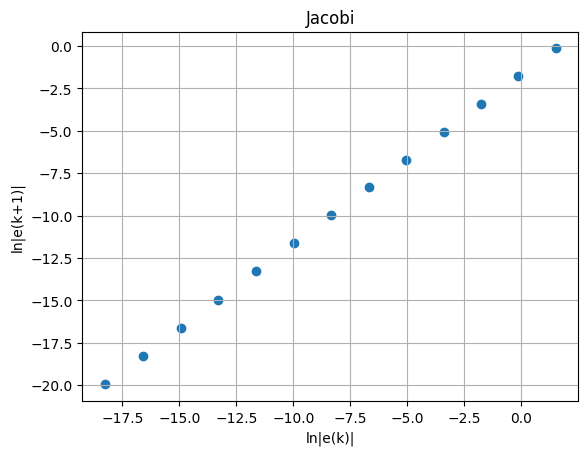

In [102]:
#Jacobi
x,k,y=jacobi(A,b,x0,1e2,tol=1.0e-9)
print("sol=",x)
print("iter Jacobi=",k)

err=np.zeros(k)
for i in range(k):
  err[i]=np.log(np.linalg.norm(y[:, i:i+1]-x_exacta))

m1, b1= np.polyfit(err[0:k-1], err[1: k], 1)
print("velocidad de convergencia jacobi=", m1)
plt.grid()
plt.title("Jacobi")
plt.xlabel('ln|e(k)|')
plt.ylabel('ln|e(k+1)|')
plt.scatter(err[0:k-1], err[1: k])

sol= [[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]
iter seidel= 14
velocidad de convergencia seidel= 1.0019447292264523


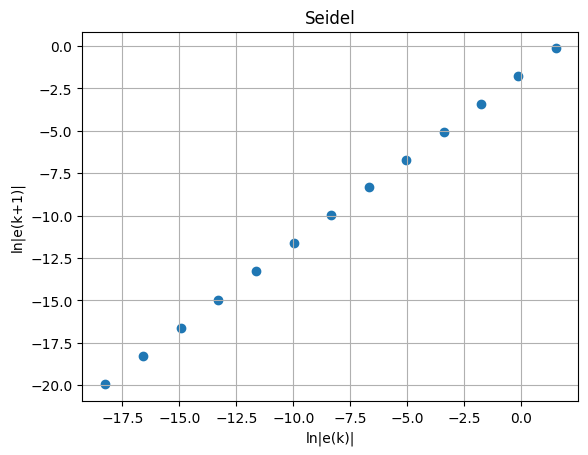

In [103]:
#Seidel
x2,k2,y2=seidel(A,b,x0,1e2,tol=1.0e-9)
print("sol=",x2)
print("iter seidel=",k2)

err2=np.zeros(k2)
for i in range(k2):
  err2[i]=np.log(np.linalg.norm(y2[:, i:i+1]-x_exacta))

m2, b2= np.polyfit(err2[0:k2-1], err2[1: k2], 1)
print("velocidad de convergencia seidel=", m2)
plt.grid()
plt.title("Seidel")
plt.xlabel('ln|e(k)|')
plt.ylabel('ln|e(k+1)|')
plt.scatter(err2[0:k2-1], err2[1: k2])


sol= [[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]
iter= 15
velocidad de convergencia descenso profundo= 0.9671696375436762


/tmp/ipykernel_740/1344181926.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  if(math.sqrt(np.dot(r.T,r))) < tol:


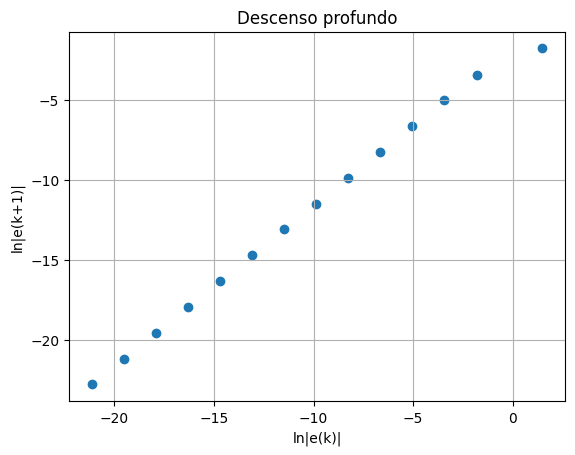

In [104]:
#Descenso profundo
def Av(x):
    return A@x
##
x3,k3,y3 = steep(Av,x0,b,tol=1.0e-9,kmax=1e5)
##

print("sol=",x3)
print("iter=",k3)

err3=np.zeros(k3)
for i in range(k3):
  err3[i]=np.log(np.linalg.norm(y3[:, i:i+1]-x_exacta))

m3, b3= np.polyfit(err3[0:k3-1], err3[1: k3], 1)
print("velocidad de convergencia descenso profundo=", m3)
plt.grid()
plt.title("Descenso profundo")
plt.xlabel('ln|e(k)|')
plt.ylabel('ln|e(k+1)|')
plt.scatter(err3[0:k3-1], err3[1: k3])
